# Praktikum 2 – Deep Learning: Image Classification (Monkeypox)


**Deskripsi Praktikum**

Pada tugas praktikum ini, peserta diminta untuk membuat model Artificial Intelligence (AI) dengan teknik klasifikasi menggunakan dataset Monkeypox yang telah disediakan.

Dataset dapat diunduh melalui file yang telah diberikan atau diakses melalui tautan berikut: https://www.kaggle.com/datasets/nafin59/monkeypox-skin-lesion-dataset


**Tujuan Praktikum**
1. Memahami konsep dasar Image Classification menggunakan Deep Learning.
2. Melakukan preprocessing dan persiapan dataset gambar lesi kulit.
3. Membangun dan melatih model CNN untuk mengklasifikasikan gambar lesi kulit ke dalam kelas Monkeypox dan Others.
4. Mengevaluasi performa model menggunakan metrik accuracy, precision, recall, dan confusion matrix.
5. Menguji model menggunakan gambar baru untuk mengetahui kemampuan model dalam mengklasifikasikan lesi kulit ke dalam kelas Monkeypox dan Others.

**Business Understanding**:
Membangun model image classification untuk mengklasifikasikan gambar lesi kulit ke dalam dua kelas, yaitu Monkeypox dan Others, serta mengevaluasi performa model menggunakan metrik accuracy, precision, recall, dan F1-score.

**Expected Output**:
Model klasifikasi citra yang mampu membedakan lesi kulit Monkeypox dan Others dengan performa yang baik berdasarkan hasil evaluasi.

**Nama Kelompok:**
`Orvaire`

**Nama Anggota - NPM:**
1. Azhar Aulia Priatna - 1402024013

2. Aidan Pitra Habibie - 1402024006

3. Muhammad Daffa Indra Pradana - 1402024032


In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nafin59/monkeypox-skin-lesion-dataset")

print("Path to dataset files:", path)

100%|██████████| 46.3M/46.3M [00:00<00:00, 146MB/s] 

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/nafin59/monkeypox-skin-lesion-dataset/versions/4


In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image
import seaborn as sns
sns.set_style('whitegrid')
import os
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# A. Data Understanding

### Memahami struktur folder

In [18]:
os.listdir(path)

['Monkeypox_Dataset_metadata.csv',
 'Original Images',
 'Augmented Images',
 'Fold1']

In [4]:
main_dir = os.path.join(path, 'Fold1', 'Fold1', 'Fold1')
os.listdir(main_dir)

['Train', 'Test', 'Val']

In [6]:
train_dir = os.path.join(main_dir, 'Train')
val_dir = os.path.join(main_dir, 'Val')
test_dir = os.path.join(main_dir, 'Test')

### Analisis Distribusi Kelas

In [11]:
for set_type, directory in [('Train', train_dir), ('Val', val_dir), ('Test', test_dir)]:
    print(f'{set_type} Set:')
    for label in sorted(os.listdir(directory)):
        n = len(os.listdir(os.path.join(directory, label)))
        print(f'{label}: {n} gambar')
    print()

Train Set:
Monkeypox: 980 gambar
Others: 1162 gambar

Val Set:
Monkeypox: 168 gambar
Others: 252 gambar

Test Set:
Monkeypox: 20 gambar
Others: 25 gambar



### Visualisasi Distribusi Kelas

In [23]:
df_train_dist = pd.DataFrame({'Class':['Monkeypox','Others'], 'Counts':[980, 1162]})
df_val_dist = pd.DataFrame({'Class':['Monkeypox','Others'], 'Counts':[168 , 252 ]})
df_test_dist = pd.DataFrame({'Class':['Monkeypox','Others'], 'Counts':[20 , 25 ]})

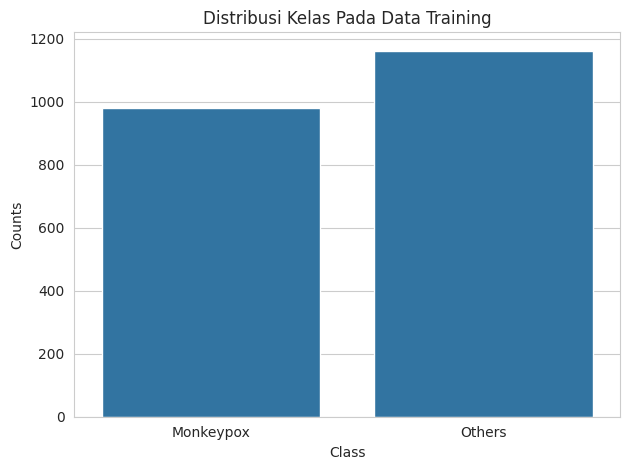

,Class,Counts
0,Monkeypox,980
1,Others,1162


In [39]:
sns.barplot(x='Class', y='Counts', data=df_train_dist)
plt.title('Distribusi Kelas Pada Data Training')
plt.tight_layout()
plt.show()
df_train_dist

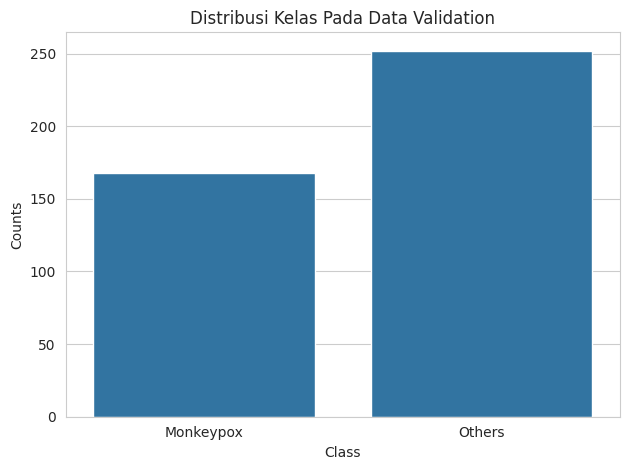

,Class,Counts
0,Monkeypox,168
1,Others,252


In [40]:
sns.barplot(x='Class', y='Counts', data=df_val_dist)
plt.title('Distribusi Kelas Pada Data Validation')
plt.tight_layout()
plt.show()
df_val_dist

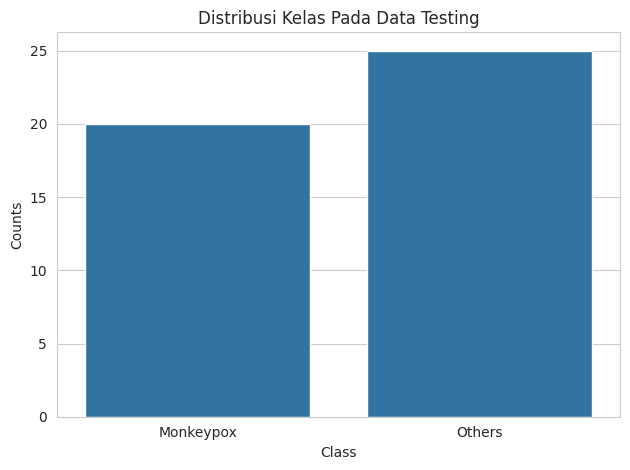

,Class,Counts
0,Monkeypox,20
1,Others,25


In [41]:
sns.barplot(x='Class', y='Counts', data=df_test_dist)
plt.title('Distribusi Kelas Pada Data Testing')
plt.tight_layout()
plt.show()
df_test_dist

### Analisis Dimensi Gambar

In [50]:
train_mkpox_img_path = os.path.join(train_dir, 'Monkeypox', os.listdir(os.path.join(train_dir, 'Monkeypox'))[7])
train_other_img_path = os.path.join(train_dir, 'Others', os.listdir(os.path.join(train_dir, 'Others'))[7])

In [51]:
mkpox_arr_img = mpimg.imread(train_mkpox_img_path)
mkpox_arr_img

array([[[188, 156, 143],
        [184, 152, 139],
        [177, 145, 132],
        ...,
        [ 73,  45,  24],
        [ 74,  46,  25],
        [ 74,  46,  25]],

       [[211, 179, 166],
        [207, 175, 162],
        [201, 169, 156],
        ...,
        [ 69,  41,  20],
        [ 70,  42,  21],
        [ 70,  42,  21]],

       [[213, 183, 172],
        [212, 182, 171],
        [211, 181, 170],
        ...,
        [ 64,  36,  15],
        [ 65,  37,  16],
        [ 66,  38,  17]],

       ...,

       [[146, 118, 114],
        [152, 124, 120],
        [153, 125, 121],
        ...,
        [ 24,   9,   2],
        [ 23,   8,   1],
        [ 22,   7,   0]],

       [[154, 126, 122],
        [158, 130, 126],
        [157, 129, 125],
        ...,
        [ 24,   9,   2],
        [ 22,   7,   0],
        [ 21,   6,   0]],

       [[147, 119, 115],
        [151, 123, 119],
        [152, 124, 120],
        ...,
        [ 24,   9,   2],
        [ 23,   8,   1],
        [ 21,   6,   0]]

In [52]:
mkpox_arr_img.shape

(224, 224, 3)

### Menampilkan Contoh Gambar

In [53]:
mkpox_img = Image.open(train_mkpox_img_path)
other_img = Image.open(train_other_img_path)

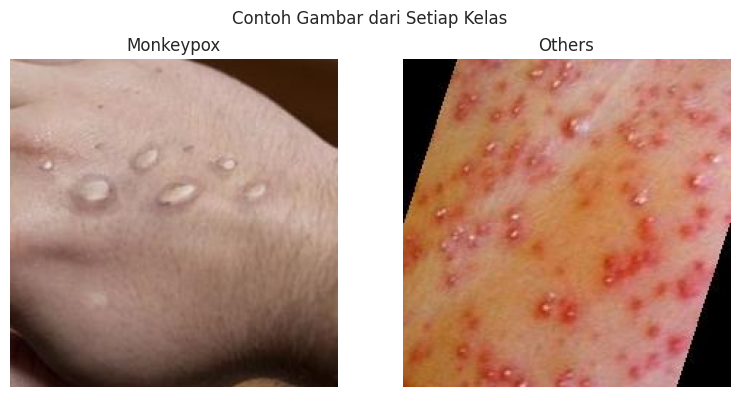

In [68]:
fig, ax = plt.subplots(1,2, figsize=(8,4))
ax[0].imshow(mkpox_img)
ax[0].set_title('Monkeypox')
ax[0].axis('off')

ax[1].imshow(other_img)
ax[1].set_title('Others')
ax[1].axis('off')

plt.suptitle("Contoh Gambar dari Setiap Kelas")
plt.tight_layout()
plt.show()

# B. Data Preparation

In [71]:
CLASS_NAMES = ['Monkeypox', 'Others']
# Ukuran gambar yang digunakan oleh CNN
IMG_SIZE = (224, 224)
# Jumlah gambar yang diproses dalam satu batch
BATCH_SIZE = 32
# Seed agar pembagian data dapat direproduksi
SEED = 42

In [75]:
datagen = ImageDataGenerator(rescale=1./255)
train_generator = datagen.flow_from_directory(
    train_dir,
    target_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    class_mode = 'binary',
    classes = CLASS_NAMES,
    shuffle = True,
    seed = SEED
)
val_generator = datagen.flow_from_directory(
    val_dir,
    target_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    class_mode = 'binary',
    classes = CLASS_NAMES,
    shuffle = False,
    seed = SEED
)
test_generator = datagen.flow_from_directory(
    test_dir,
    target_size = IMG_SIZE,
    batch_size = BATCH_SIZE,
    class_mode = 'binary',
    classes = CLASS_NAMES,
    shuffle = False,
    seed = SEED
)
print("Kelas:", train_generator.class_indices)

Found 2142 images belonging to 2 classes.
Found 420 images belonging to 2 classes.
Found 45 images belonging to 2 classes.
Kelas: {'Monkeypox': 0, 'Others': 1}


In [82]:
x_batch, y_batch = next(train_generator)
print('Ukuran batch gambar:', x_batch.shape)
print('Ukuran batch label:', y_batch.shape)
print('Range piksel:', x_batch.min(), '-', x_batch.max())
print('Jumlah batch/epoch:', len(train_generator))

Ukuran batch gambar: (32, 224, 224, 3)
Ukuran batch label: (32,)
Range piksel: 0.0 - 1.0
Jumlah batch/epoch: 67


# C. Modeling

# D. Evaluation